# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [71]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Games/")

In [ ]:
%precision 3

import numpy as np
np.random.seed(1000)  # for reproducibility

In [73]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

In [ ]:
def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)

In [75]:
# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

-1
1
-1
-1
1


In [76]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

In [77]:
u = playouts(board, action = 0, N = 100)

print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

print(f"win probability:  {sum(np.array(u) == +1)/len(u)}")
print(f"loss probability: {sum(np.array(u) == -1)/len(u)}")
print(f"draw probability: {sum(np.array(u) == 0)/len(u)}")

Playout results: [-1, 1, 1, -1, -1, -1, 0, -1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, -1, 1, -1, 1, -1, 1, -1, 1, 1, -1, -1, 1, -1, 1, 1, 1, -1, 0, 1, -1, 1, 0, -1, 1, 1, 1, 1, 1, 1, 0, -1, 0, 1, 1, 1, 1, 1, 1, -1, -1, 1, 1, 1, 1, 1, -1, 1, -1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, -1, -1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, -1, 1, 1]
mean utility: 0.4
win probability:  0.63
loss probability: 0.23
draw probability: 0.14


__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

In [78]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get)
    return action

board = empty_board()
display(board)
%time print(pmcs(board, N = 100))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.545,
 1: -0.364,
 2: 0.091,
 3: 0.091,
 4: 0.182,
 5: 0.364,
 6: 0.000,
 7: 0.455,
 8: 0.636}

8
CPU times: user 21.2 ms, sys: 32 ms, total: 53.2 ms
Wall time: 47.1 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.318,
 1: 0.195,
 2: 0.332,
 3: 0.160,
 4: 0.492,
 5: 0.228,
 6: 0.348,
 7: 0.192,
 8: 0.361}

4
CPU times: user 1.68 s, sys: 39.6 ms, total: 1.72 s
Wall time: 1.72 s


Looks like the center and the corners are a lot better.

## Some Tests

### x is about to win (play 8)


Board:


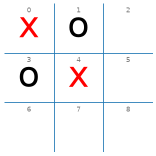


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.900, 5: 0.650, 6: 0.800, 7: 0.500, 8: 1.000}

8

CPU times: user 10.2 ms, sys: 8.12 ms, total: 18.3 ms
Wall time: 16.4 ms


In [79]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### o is about to win

Board:


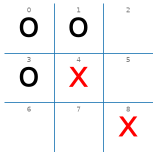


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: -0.200, 5: -0.280, 6: 0.040, 7: -0.840}

6

CPU times: user 7.88 ms, sys: 12.2 ms, total: 20.1 ms
Wall time: 18.2 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: 0.000, 5: -0.632, 6: -0.080, 7: -0.672}

2

CPU times: user 72.3 ms, sys: 20.1 ms, total: 92.4 ms
Wall time: 86.8 ms


In [80]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

### x can draw if it chooses 7

Board:


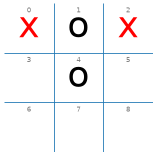


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: 0.000, 5: -0.150, 6: -0.300, 7: 0.250, 8: -0.150}

7

CPU times: user 9.93 ms, sys: 8.12 ms, total: 18 ms
Wall time: 17.1 ms


In [81]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### Empty board: Only a draw an be guaranteed

Board:


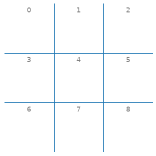


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.364,
 1: 0.202,
 2: 0.398,
 3: 0.220,
 4: 0.519,
 5: 0.216,
 6: 0.330,
 7: 0.245,
 8: 0.326}

4

CPU times: user 943 ms, sys: 36.5 ms, total: 980 ms
Wall time: 969 ms


In [82]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

### A bad situation

Board:


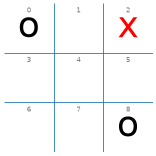


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -0.500, 3: -0.500, 4: -0.188, 5: -0.875, 6: -0.500, 7: -0.688}

4

CPU times: user 15.4 ms, sys: 7.99 ms, total: 23.4 ms
Wall time: 21.8 ms


In [83]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

Define agents with a playout budget of 10, 100 and 1000 playouts.

In [84]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action

### Compare 10 playouts with a random player

In [85]:
DEBUG = 0
print("PMCS (10) vs. random:")
%time display(play(pmcs10_player, random_player))

print()
print("random vs. PMCS (10)")
%time display(play(random_player, pmcs10_player))

PMCS (10) vs. random:


{'x': 92, 'o': 7, 'd': 1}

CPU times: user 501 ms, sys: 56.5 ms, total: 557 ms
Wall time: 540 ms

random vs. PMCS (10)


{'x': 22, 'o': 68, 'd': 10}

CPU times: user 462 ms, sys: 52.2 ms, total: 514 ms
Wall time: 496 ms


### Compare 100 playouts with a random player

In [86]:
DEBUG = 0
print("PMCS (100) vs. random:")
%time display(play(pmcs100_player, random_player))

print()
print("random vs. PMCS (100)")
%time display(play(random_player, pmcs100_player))

PMCS (100) vs. random:


{'x': 93, 'o': 1, 'd': 6}

CPU times: user 7.55 s, sys: 74.6 ms, total: 7.62 s
Wall time: 7.59 s

random vs. PMCS (100)


{'x': 3, 'o': 89, 'd': 8}

CPU times: user 4.75 s, sys: 15.8 ms, total: 4.77 s
Wall time: 4.76 s


### Compare 10 playouts vs 100 playouts

In [87]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 90, 'o': 3, 'd': 7}

CPU times: user 6.1 s, sys: 117 ms, total: 6.21 s
Wall time: 6.17 s

PMCS (10) vs. PMCS (100)


{'x': 39, 'o': 49, 'd': 12}

CPU times: user 4.67 s, sys: 23.9 ms, total: 4.69 s
Wall time: 4.69 s


**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games. It will play close to optimal.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.